<a href="https://colab.research.google.com/github/soilzx/MedQuAD-RAG/blob/main/Milestone%203/Milestone_3_Part1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data Loading, Cleaning, and Splitting

In [3]:
import pandas as pd
import kagglehub
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from torch.utils.data import TensorDataset, DataLoader
from sentence_transformers import SentenceTransformer

def load_data():
  df = pd.read_parquet("hf://datasets/lavita/MedQuAD/data/train-00000-of-00001-e36383d177026d53.parquet")

  return df

def load_data2():
  path = kagglehub.dataset_download("pythonafroz/medquad-medical-question-answer-for-ai-research")
  data_dir = Path(path)
  df = pd.read_csv(data_dir / "medquad.csv")

  return df

def mergeAnswers(df1, df2):
  df3 = df1.copy()
  lookup = (
      df2.loc[df2["answer"].notna(), ["question", "answer"]]
        .drop_duplicates(subset="question")
        .set_index("question")["answer"]
  )
  missing = df3["answer"].isna() | df3["answer"].fillna("").str.strip().eq("")
  df3.loc[missing, "answer"] = df3.loc[missing, "question"].map(lookup)

  return df3

def resolving_missing_values_of_synonyms(df1, df2):
  synonyms_from_df2 = (
    df2.dropna(subset=["synonyms"])
       .drop_duplicates(subset=["question"])
       .set_index("question")["synonyms"]
)
  missing = df1["synonyms"].isna()
  df1.loc[missing, "synonyms"] = (
      df1.loc[missing, "question"].map(synonyms_from_df2)
  )
  return df1

def preprocess(df1, df2):
  # the answer columns has many missing values, so I merged two different published dataset (both are the same but with different sorces) to minimize the losses of info
  df = mergeAnswers(df1, df2)
  # around 15k value in the category column is None, so will fill them with the "Other" Value
  df["category"] = df["category"].fillna("Other")
  #there are some unuseful columns, so I throw it in the trash :), umls_semantic_group values is either disorder or None (unuseful!)
  usefulness_columns = ["document_id", "document_url", "umls_cui", "umls_semantic_types", "umls_semantic_group"]
  df = df.drop(columns = usefulness_columns)
  #if the record does not provide an answer value, it is useless so we will just drop it
  df.dropna(subset = "answer", inplace=True)
  #the merged answers are copies of question/answer pairs we already have, so we drop the duplicates
  df["answer"] = df["answer"].str.strip()
  df = df.drop_duplicates(subset = ["question", "answer"])
  #stratify needs enough records in each question_type ("support groups" has only 1 record)
  counts = df["question_type"].value_counts()
  df = df[df["question_type"].isin(counts[counts >= 10].index)]
  #the kaggle dataset has no synonyms column, and synonyms is not an input to the model, so this step is skipped
  # df = resolving_missing_values_of_synonyms(df, df2)
  return df

def show_samples(df):
  samples = df.groupby("question_type").head(1)
  for i, row in samples.iterrows():
    print("[" + row["question_type"] + "]")
    print("Q:", row["question"])
    print("A:", row["answer"][:150], "...")
    print()

  return samples

def split(df):
  X = df.drop(columns = "answer")
  y = df["answer"]
  stratify_column = df["question_type"]
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify = stratify_column, random_state = 42)
  X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.2, stratify = X_train["question_type"], random_state = 42)

  return X_train, X_test, X_val, y_train, y_test, y_val

def embed(texts, model):
  #the encoder is pretrained and frozen, it turns each text into a vector of 384 numbers
  vectors = model.encode(list(texts), batch_size = 64, show_progress_bar = True)

  return vectors

def encode_labels(X_train, X_test, X_val):
  label_encoder = LabelEncoder()
  train_labels = label_encoder.fit_transform(X_train["question_type"])
  test_labels = label_encoder.transform(X_test["question_type"])
  val_labels = label_encoder.transform(X_val["question_type"])

  return train_labels, test_labels, val_labels, label_encoder

def normalize(train, test, val):
  scaler = StandardScaler()
  train = scaler.fit_transform(train)
  test = scaler.transform(test)
  val = scaler.transform(val)

  return train, test, val, scaler

def to_tensors(X, y):
  X = torch.tensor(X, dtype = torch.float32)
  y = torch.tensor(y, dtype = torch.float32)

  return X, y

def make_loaders(X_train, y_train, X_test, y_test, X_val, y_val, batch_size = 64):
  #only the training data is shuffled
  train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size = batch_size, shuffle = True)
  test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size = batch_size, shuffle = False)
  val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size = batch_size, shuffle = False)

  return train_loader, test_loader, val_loader


df1 = load_data()
df2 = load_data2()
df = preprocess(df1, df2)
print("clean shape:", df.shape)
samples = show_samples(df)

X_train, X_test, X_val, y_train, y_test, y_val = split(df)
print("train:", len(X_train), " test:", len(X_test), " val:", len(X_val))

Using Colab cache for faster access to the 'medquad-medical-question-answer-for-ai-research' dataset.
clean shape: (16358, 8)
[information]
Q: What is (are) keratoderma with woolly hair ?
A: Keratoderma with woolly hair is a group of related conditions that affect the skin and hair and in many cases increase the risk of potentially life-th ...

[frequency]
Q: How many people are affected by keratoderma with woolly hair ?
A: Keratoderma with woolly hair is rare; its prevalence worldwide is unknown.  Type I (Naxos disease) was first described in families from the Greek isla ...

[genetic changes]
Q: What are the genetic changes related to keratoderma with woolly hair ?
A: Mutations in the JUP, DSP, DSC2, and KANK2 genes cause keratoderma with woolly hair types I through IV, respectively. The JUP, DSP, and DSC2 genes pro ...

[inheritance]
Q: Is keratoderma with woolly hair inherited ?
A: Most cases of keratoderma with woolly hair have an autosomal recessive pattern of inheritance, which 

# 2. Tokenization and Vocabulary Building

In [4]:
import re
from collections import Counter

def tokenize(text):
    # Lowercase and separate words from punctuation.
    return re.findall(r"\w+|[^\w\s]", str(text).lower())

# Learn the vocabulary using training questions only.
token_counts = Counter(
    token
    for question in X_train["question"]
    for token in tokenize(question)
)

# Special tokens:
# PAD fills shorter questions.
# UNK represents words missing from the training vocabulary.
vocab = {"<PAD>": 0, "<UNK>": 1}

for token, count in token_counts.items():
    if count >= 2:
        vocab[token] = len(vocab)

print("Vocabulary size:", len(vocab))

example = X_train["question"].iloc[0]
tokens = tokenize(example)
token_ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

print("Question:", example)
print("Tokens:", tokens)
print("Token IDs:", token_ids)

Vocabulary size: 2848
Question: What are the symptoms of Williams syndrome ?
Tokens: ['what', 'are', 'the', 'symptoms', 'of', 'williams', 'syndrome', '?']
Token IDs: [2, 3, 4, 5, 6, 7, 8, 9]


# 3. Question Encoding and Padding

In [5]:
import torch

train_lengths = [
    len(tokenize(question))
    for question in X_train["question"]
]

MAX_LENGTH = max(train_lengths)

def encode_question(question):
    tokens = tokenize(question)
    ids = [vocab.get(token, vocab["<UNK>"]) for token in tokens]

    ids = ids[:MAX_LENGTH]
    ids += [vocab["<PAD>"]] * (MAX_LENGTH - len(ids))

    return ids

# Token IDs must be integers for the embedding layer.
X_train_ids = torch.tensor(
    [encode_question(q) for q in X_train["question"]],
    dtype=torch.long
)

X_val_ids = torch.tensor(
    [encode_question(q) for q in X_val["question"]],
    dtype=torch.long
)

print("Maximum training length:", MAX_LENGTH)
print("Training shape:", X_train_ids.shape)
print("Validation shape:", X_val_ids.shape)
print("First encoded question:", X_train_ids[0].tolist())

# Check how much training text our vocabulary represents.
train_tokens = sum(token_counts.values())
unknown_tokens = sum(
    count for token, count in token_counts.items()
    if token not in vocab
)
print(f"Training UNK rate: {unknown_tokens / train_tokens:.2%}")

Maximum training length: 34
Training shape: torch.Size([10468, 34])
Validation shape: torch.Size([2618, 34])
First encoded question: [2, 3, 4, 5, 6, 7, 8, 9, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Training UNK rate: 1.24%


# 4. Answer Embeddings and Target Normalization

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import StandardScaler

# Fixed encoder used only to create the answer targets.
target_encoder = SentenceTransformer(
    "all-MiniLM-L6-v2",
    device="cuda"
)
target_encoder.eval()

y_train_emb = target_encoder.encode(
    y_train.tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
)

y_val_emb = target_encoder.encode(
    y_val.tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
)

# Learn normalization statistics from training targets only.
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train_emb)
y_val_scaled = y_scaler.transform(y_val_emb)

y_train_t = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_t = torch.tensor(y_val_scaled, dtype=torch.float32)

print("Training targets:", y_train_t.shape)
print("Validation targets:", y_val_t.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/164 [00:00<?, ?it/s]

Batches:   0%|          | 0/41 [00:00<?, ?it/s]

Training targets: torch.Size([10468, 384])
Validation targets: torch.Size([2618, 384])


# 5. Data Augmentation and Five Sample Comparisons

In [8]:
import re
import pandas as pd

def augment_framing(question):
    return "Please answer this question: " + str(question).strip()

def augment_rephrasing(question):
    question = str(question).strip()

    # Replace only the opening phrase.
    replacements = [
        (r"^what are the symptoms of\b",
         "Which symptoms are associated with"),

        (r"^what causes\b",
         "What leads to"),

        (r"^what is \(are\)\s+",
         "Could you explain "),

        (r"^what is\b",
         "Could you explain"),

        (r"^what are\b",
         "Could you describe"),
    ]

    for pattern, replacement in replacements:
        if re.search(pattern, question, flags=re.IGNORECASE):
            return re.sub(
                pattern,
                replacement,
                question,
                count=1,
                flags=re.IGNORECASE
            )

    # Preserve unfamiliar question structures.
    return "I would like to know: " + question

# Five training samples, each with two augmented versions.
examples = X_train["question"].sample(n=5, random_state=42)

augmentation_examples = pd.DataFrame({
    "Original": examples.tolist(),
    "Augmentation 1": [
        augment_framing(q) for q in examples
    ],
    "Augmentation 2": [
        augment_rephrasing(q) for q in examples
    ],
})

pd.set_option("display.max_colwidth", None)
display(augmentation_examples)

,Original,Augmentation 1,Augmentation 2
0,What are the treatments for keratitis-ichthyosis-deafness syndrome ?,Please answer this question: What are the treatments for keratitis-ichthyosis-deafness syndrome ?,Could you describe the treatments for keratitis-ichthyosis-deafness syndrome ?
1,What are the treatments for Familial atrial fibrillation ?,Please answer this question: What are the treatments for Familial atrial fibrillation ?,Could you describe the treatments for Familial atrial fibrillation ?
2,What are the symptoms of Russell-Silver syndrome ?,Please answer this question: What are the symptoms of Russell-Silver syndrome ?,Which symptoms are associated with Russell-Silver syndrome ?
3,What to do for Hemochromatosis ?,Please answer this question: What to do for Hemochromatosis ?,I would like to know: What to do for Hemochromatosis ?
4,What is (are) Unverricht-Lundborg disease ?,Please answer this question: What is (are) Unverricht-Lundborg disease ?,Could you explain Unverricht-Lundborg disease ?


# 6. Applying Augmentation to All Training Questions

In [9]:
original_questions = X_train["question"].tolist()

framed_questions = [
    augment_framing(q) for q in original_questions
]

rephrased_questions = [
    augment_rephrasing(q) for q in original_questions
]

all_train_questions = (
    original_questions + framed_questions + rephrased_questions
)

# Each version keeps the same answer target.
all_train_targets = torch.cat(
    [y_train_t, y_train_t, y_train_t], dim=0
)

print("Training questions:", len(all_train_questions))
print("Answer targets:", all_train_targets.shape)

Training questions: 31404
Answer targets: torch.Size([31404, 384])


# 7. Updating the Vocabulary and Encoding Augmented Questions

In [10]:
augmentation_counts = Counter(
    token
    for question in all_train_questions
    for token in tokenize(question)
)

for token in augmentation_counts:
    if token not in token_counts and token not in vocab:
        vocab[token] = len(vocab)

MAX_LENGTH = max(
    len(tokenize(q)) for q in all_train_questions
)

all_train_ids = torch.tensor(
    [encode_question(q) for q in all_train_questions],
    dtype=torch.long
)

X_train_ids = torch.tensor(
    [encode_question(q) for q in original_questions],
    dtype=torch.long
)

X_val_ids = torch.tensor(
    [encode_question(q) for q in X_val["question"]],
    dtype=torch.long
)

print("Vocabulary size:", len(vocab))
print("Maximum length:", MAX_LENGTH)
print("Augmented training:", all_train_ids.shape)
print("Validation:", X_val_ids.shape)

Vocabulary size: 2858
Maximum length: 40
Augmented training: torch.Size([31404, 40])
Validation: torch.Size([2618, 40])


# 8. Creating Training and Validation Data Loaders

In [11]:
from torch.utils.data import TensorDataset, DataLoader
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
save_dir = Path("cnn_results")
save_dir.mkdir(exist_ok=True)

train_loader = DataLoader(
    TensorDataset(all_train_ids, all_train_targets),
    batch_size=64,
    shuffle=True
)

train_eval_loader = DataLoader(
    TensorDataset(X_train_ids, y_train_t),
    batch_size=128,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(X_val_ids, y_val_t),
    batch_size=128,
    shuffle=False
)

print("Device:", device)
print("Training batches:", len(train_loader))

Device: cuda
Training batches: 491


# 8. Creating Training and Validation Data Loaders

# 9. Building the CNN from Scratch

In [12]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, dropout=0.2):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size, 64, padding_idx=0
        )

        self.features = nn.Sequential(
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2, ceil_mode=True),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv1d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveMaxPool1d(1)
        )

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 384)
        )

    def forward(self, x):
        x = self.embedding(x)

        # Conv1d expects: batch, embedding channels, sequence length.
        x = x.transpose(1, 2)

        x = self.features(x)
        return self.head(x)


model = TextCNN(len(vocab)).to(device)

with torch.no_grad():
    output = model(X_train_ids[:2].to(device))

print("Output shape:", output.shape)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

Output shape: torch.Size([2, 384])
Trainable parameters: 347648


# 10. CNN Architecture, Output Shapes, and Parameter Counts

,Layer,Output shape,Trainable parameters
0,Input token IDs,B × 40,0
1,Embedding,B × 40 × 64,182912
2,Transpose,B × 64 × 40,0
3,Conv1 + ReLU,B × 64 × 40,12352
4,Conv2 + ReLU,B × 64 × 40,12352
5,Max pooling,B × 64 × 20,0
6,Conv3 + ReLU,B × 128 × 20,24704
7,Conv4 + ReLU,B × 128 × 20,49280
8,Global max pooling + Flatten,B × 128,0
9,Linear + ReLU + Dropout,B × 128,16512


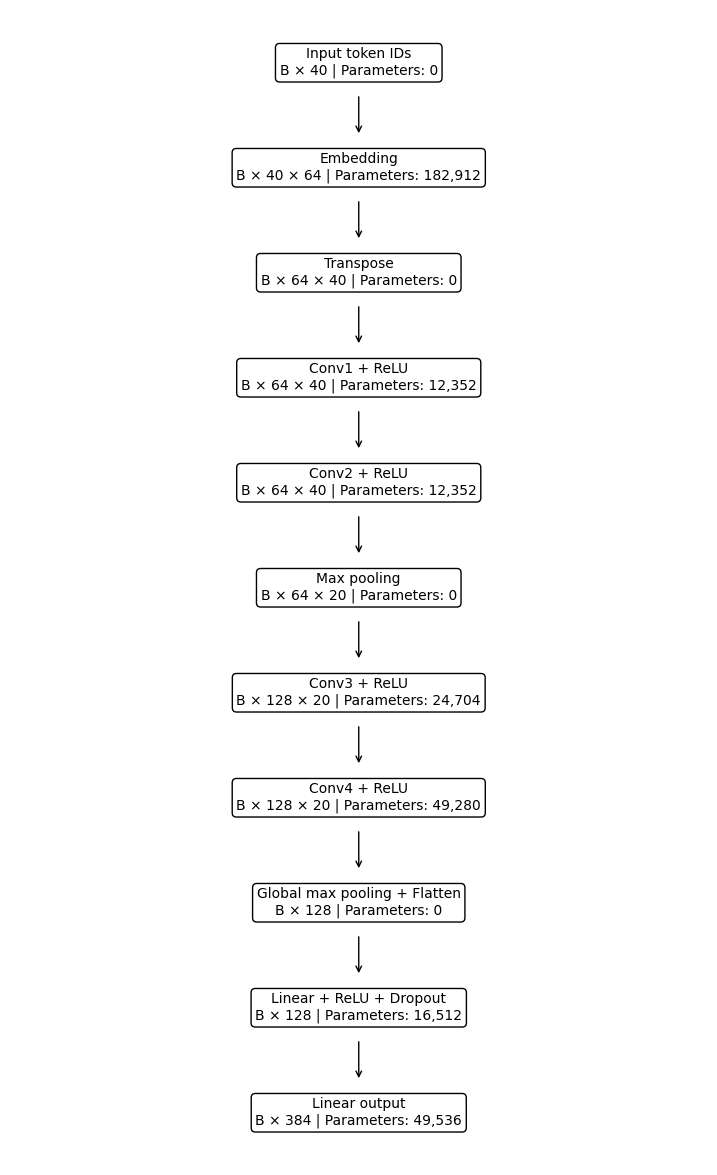

In [13]:
def parameter_count(layer):
    return sum(p.numel() for p in layer.parameters())

L = MAX_LENGTH
P = (L + 1) // 2

architecture = pd.DataFrame([
    ["Input token IDs", f"B × {L}", 0],
    ["Embedding", f"B × {L} × 64", parameter_count(model.embedding)],
    ["Transpose", f"B × 64 × {L}", 0],
    ["Conv1 + ReLU", f"B × 64 × {L}", parameter_count(model.features[0])],
    ["Conv2 + ReLU", f"B × 64 × {L}", parameter_count(model.features[2])],
    ["Max pooling", f"B × 64 × {P}", 0],
    ["Conv3 + ReLU", f"B × 128 × {P}", parameter_count(model.features[5])],
    ["Conv4 + ReLU", f"B × 128 × {P}", parameter_count(model.features[7])],
    ["Global max pooling + Flatten", "B × 128", 0],
    ["Linear + ReLU + Dropout", "B × 128", parameter_count(model.head[1])],
    ["Linear output", "B × 384", parameter_count(model.head[4])]
], columns=["Layer", "Output shape", "Trainable parameters"])

display(architecture)
architecture.to_csv(save_dir / "architecture.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 15))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, len(architecture))

for i, row in architecture.iterrows():
    y = len(architecture) - i - 0.5

    text = (
        f"{row['Layer']}\n"
        f"{row['Output shape']} | Parameters: {row['Trainable parameters']:,}"
    )

    ax.text(
        0.5, y, text,
        ha="center", va="center", fontsize=10,
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="black")
    )

    if i < len(architecture) - 1:
        ax.annotate(
            "", xy=(0.5, y - 0.7), xytext=(0.5, y - 0.3),
            arrowprops=dict(arrowstyle="->")
        )

plt.savefig(save_dir / "architecture.png", bbox_inches="tight")
plt.show()

# 11. Training and Evaluation Functions

In [14]:
def evaluate(model, loader):
    model.eval()
    squared_error = 0
    total_values = 0

    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)

            prediction = model(X)

            squared_error += ((prediction - y) ** 2).sum().item()
            total_values += y.numel()

    mse = squared_error / total_values
    rmse = mse ** 0.5

    return mse, rmse


def train_cnn(lr, dropout, name, epochs=25, patience=None):
    torch.manual_seed(42)

    model = TextCNN(len(vocab), dropout=dropout).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr,
        weight_decay=0.0001
    )

    loss_fn = nn.MSELoss()
    history = []

    best_val_rmse = float("inf")
    waiting = 0

    for epoch in range(1, epochs + 1):
        model.train()

        for X, y in train_loader:
            X = X.to(device)
            y = y.to(device)

            optimizer.zero_grad()

            prediction = model(X)
            loss = loss_fn(prediction, y)

            loss.backward()
            optimizer.step()

        train_loss, train_rmse = evaluate(model, train_eval_loader)
        val_loss, val_rmse = evaluate(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_rmse": train_rmse,
            "val_loss": val_loss,
            "val_rmse": val_rmse
        })

        # Save the logs after every epoch.
        pd.DataFrame(history).to_csv(
            save_dir / f"{name}_history.csv", index=False
        )

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            waiting = 0

            torch.save(
                model.state_dict(),
                save_dir / f"{name}_best.pt"
            )
        else:
            waiting += 1

        print(
            f"{name} | Epoch {epoch}/{epochs} | "
            f"Train RMSE: {train_rmse:.4f} | "
            f"Val RMSE: {val_rmse:.4f}",
            flush=True
        )

        if patience is not None and waiting >= patience:
            print("Early stopping.")
            break

    # Keep the final epoch for comparison.
    torch.save(
        model.state_dict(),
        save_dir / f"{name}_last.pt"
    )

    # Restore the checkpoint with the lowest validation RMSE.
    model.load_state_dict(torch.load(
        save_dir / f"{name}_best.pt",
        map_location=device,
        weights_only=True
    ))

    return model, pd.DataFrame(history)

# 12. Hyperparameter Tuning and Best Setting Selection

In [15]:
settings = [
    {"name": "cnn_1", "lr": 0.001,  "dropout": 0.2},
    {"name": "cnn_2", "lr": 0.0005, "dropout": 0.2},
    {"name": "cnn_3", "lr": 0.0005, "dropout": 0.4}
]

results = []
histories = {}

for setting in settings:
    trained_model, history = train_cnn(
        lr=setting["lr"],
        dropout=setting["dropout"],
        name=setting["name"],
        epochs=25
    )

    histories[setting["name"]] = history
    best_epoch = history.loc[history["val_rmse"].idxmin()]

    results.append({
        **setting,
        "best_epoch": int(best_epoch["epoch"]),
        "best_val_rmse": best_epoch["val_rmse"]
    })

results_table = pd.DataFrame(results)
display(results_table)

results_table.to_csv(
    save_dir / "hyperparameter_results.csv", index=False
)

best_setting = results_table.loc[
    results_table["best_val_rmse"].idxmin()
]

print("Best setting:")
print(best_setting)

cnn_1 | Epoch 1/25 | Train RMSE: 0.9140 | Val RMSE: 0.9147
cnn_1 | Epoch 2/25 | Train RMSE: 0.8980 | Val RMSE: 0.9022
cnn_1 | Epoch 3/25 | Train RMSE: 0.8886 | Val RMSE: 0.8951
cnn_1 | Epoch 4/25 | Train RMSE: 0.8791 | Val RMSE: 0.8898
cnn_1 | Epoch 5/25 | Train RMSE: 0.8742 | Val RMSE: 0.8862
cnn_1 | Epoch 6/25 | Train RMSE: 0.8647 | Val RMSE: 0.8781
cnn_1 | Epoch 7/25 | Train RMSE: 0.8500 | Val RMSE: 0.8688
cnn_1 | Epoch 8/25 | Train RMSE: 0.8423 | Val RMSE: 0.8633
cnn_1 | Epoch 9/25 | Train RMSE: 0.8365 | Val RMSE: 0.8612
cnn_1 | Epoch 10/25 | Train RMSE: 0.8311 | Val RMSE: 0.8568
cnn_1 | Epoch 11/25 | Train RMSE: 0.8233 | Val RMSE: 0.8517
cnn_1 | Epoch 12/25 | Train RMSE: 0.8242 | Val RMSE: 0.8520
cnn_1 | Epoch 13/25 | Train RMSE: 0.8211 | Val RMSE: 0.8504
cnn_1 | Epoch 14/25 | Train RMSE: 0.8169 | Val RMSE: 0.8482
cnn_1 | Epoch 15/25 | Train RMSE: 0.8128 | Val RMSE: 0.8460
cnn_1 | Epoch 16/25 | Train RMSE: 0.8117 | Val RMSE: 0.8455
cnn_1 | Epoch 17/25 | Train RMSE: 0.8135 | Val RM

,name,lr,dropout,best_epoch,best_val_rmse
0,cnn_1,0.0010,0.2,25,0.834300
1,cnn_2,0.0005,0.2,25,0.845211
2,cnn_3,0.0005,0.4,25,0.855802


Best setting:
name              cnn_1
lr                0.001
dropout             0.2
best_epoch           25
best_val_rmse    0.8343
Name: 0, dtype: object


# 13. Training with Early Stopping Enabled

In [16]:
early_model, early_history = train_cnn(
    lr=float(best_setting["lr"]),
    dropout=float(best_setting["dropout"]),
    name="early_stopping",
    epochs=60,
    patience=7
)

best_early_epoch = early_history.loc[
    early_history["val_rmse"].idxmin()
]

print("Best early-stopping epoch:", int(best_early_epoch["epoch"]))
print("Best validation RMSE:", best_early_epoch["val_rmse"])

early_stopping | Epoch 1/60 | Train RMSE: 0.9139 | Val RMSE: 0.9146
early_stopping | Epoch 2/60 | Train RMSE: 0.8982 | Val RMSE: 0.9023
early_stopping | Epoch 3/60 | Train RMSE: 0.8883 | Val RMSE: 0.8949
early_stopping | Epoch 4/60 | Train RMSE: 0.8801 | Val RMSE: 0.8901
early_stopping | Epoch 5/60 | Train RMSE: 0.8736 | Val RMSE: 0.8860
early_stopping | Epoch 6/60 | Train RMSE: 0.8631 | Val RMSE: 0.8775
early_stopping | Epoch 7/60 | Train RMSE: 0.8516 | Val RMSE: 0.8699
early_stopping | Epoch 8/60 | Train RMSE: 0.8446 | Val RMSE: 0.8650
early_stopping | Epoch 9/60 | Train RMSE: 0.8402 | Val RMSE: 0.8638
early_stopping | Epoch 10/60 | Train RMSE: 0.8331 | Val RMSE: 0.8582
early_stopping | Epoch 11/60 | Train RMSE: 0.8266 | Val RMSE: 0.8537
early_stopping | Epoch 12/60 | Train RMSE: 0.8249 | Val RMSE: 0.8528
early_stopping | Epoch 13/60 | Train RMSE: 0.8203 | Val RMSE: 0.8502
early_stopping | Epoch 14/60 | Train RMSE: 0.8181 | Val RMSE: 0.8491
early_stopping | Epoch 15/60 | Train RMSE: 

# 14. Validation Comparison: Fixed Training and Early Stopping

In [17]:
fixed_history = histories[best_setting["name"]]
fixed_epoch = fixed_history.iloc[-1]

comparison = pd.DataFrame([
    {
        "method": "Fixed training",
        "epoch": int(fixed_epoch["epoch"]),
        "train_rmse": fixed_epoch["train_rmse"],
        "val_rmse": fixed_epoch["val_rmse"],
        "val_loss": fixed_epoch["val_loss"]
    },
    {
        "method": "Early stopping",
        "epoch": int(best_early_epoch["epoch"]),
        "train_rmse": best_early_epoch["train_rmse"],
        "val_rmse": best_early_epoch["val_rmse"],
        "val_loss": best_early_epoch["val_loss"]
    }
])

display(comparison)

comparison.to_csv(
    save_dir / "early_stopping_comparison.csv", index=False
)

,method,epoch,train_rmse,val_rmse,val_loss
0,Fixed training,25,0.795380,0.834300,0.696056
1,Early stopping,58,0.770189,0.824724,0.680169


# 15. Training and Validation Performance Curves

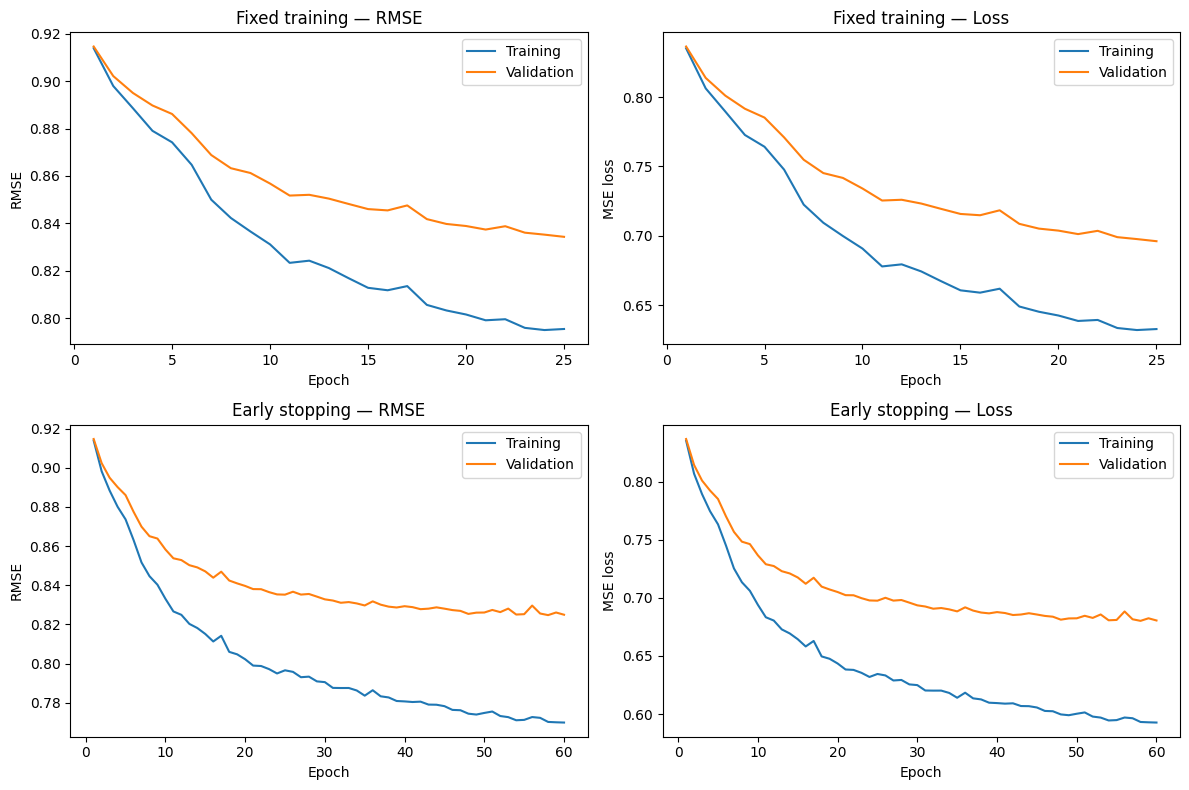

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (title, history) in enumerate([
    ("Fixed training", fixed_history),
    ("Early stopping", early_history)
]):
    axes[row, 0].plot(
        history["epoch"], history["train_rmse"], label="Training"
    )
    axes[row, 0].plot(
        history["epoch"], history["val_rmse"], label="Validation"
    )
    axes[row, 0].set_title(title + " — RMSE")
    axes[row, 0].set_ylabel("RMSE")

    axes[row, 1].plot(
        history["epoch"], history["train_loss"], label="Training"
    )
    axes[row, 1].plot(
        history["epoch"], history["val_loss"], label="Validation"
    )
    axes[row, 1].set_title(title + " — Loss")
    axes[row, 1].set_ylabel("MSE loss")

    for ax in axes[row]:
        ax.set_xlabel("Epoch")
        ax.legend()

plt.tight_layout()
plt.savefig(save_dir / "training_curves.png", dpi=150)
plt.show()

# 16. Final Model Selection and Saving

In [19]:
if best_early_epoch["val_rmse"] <= fixed_epoch["val_rmse"]:
    selected_model = early_model
    selected_method = "Early stopping"
else:
    selected_model = TextCNN(
        len(vocab),
        dropout=float(best_setting["dropout"])
    ).to(device)

    selected_model.load_state_dict(torch.load(
        save_dir / f"{best_setting['name']}_last.pt",
        map_location=device,
        weights_only=True
    ))

    selected_method = "Fixed training"

torch.save(
    selected_model.state_dict(),
    save_dir / "selected_cnn.pt"
)

# Save the information needed to rebuild and use the model.
import json

model_info = {
    "method": selected_method,
    "learning_rate": float(best_setting["lr"]),
    "dropout": float(best_setting["dropout"]),
    "vocab_size": len(vocab),
    "max_length": MAX_LENGTH,
    "vocab": vocab,
    "answer_encoder": "all-MiniLM-L6-v2",
    "target_mean": y_scaler.mean_.tolist(),
    "target_scale": y_scaler.scale_.tolist()
}

with open(save_dir / "model_info.json", "w") as file:
    json.dump(model_info, file, indent=2)

print("Selected model:", selected_method)

Selected model: Early stopping


# 17. Final Test Evaluation

In [20]:
X_test_ids = torch.tensor(
    [encode_question(q) for q in X_test["question"]],
    dtype=torch.long
)

y_test_emb = target_encoder.encode(
    y_test.tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True
)

y_test_t = torch.tensor(
    y_scaler.transform(y_test_emb),
    dtype=torch.float32
)

test_loader = DataLoader(
    TensorDataset(X_test_ids, y_test_t),
    batch_size=128,
    shuffle=False
)

test_loss, test_rmse = evaluate(selected_model, test_loader)

print("Test MSE:", round(test_loss, 4))
print("Test RMSE:", round(test_rmse, 4))

pd.DataFrame([{
    "method": selected_method,
    "test_loss": test_loss,
    "test_rmse": test_rmse
}]).to_csv(save_dir / "test_results.csv", index=False)

Batches:   0%|          | 0/52 [00:00<?, ?it/s]

Test MSE: 0.6768
Test RMSE: 0.8227


# 18. CNN and Previous MLP Comparison

In [21]:
mlp_test_rmse = 0.7246

baseline_comparison = pd.DataFrame({
    "Model": ["Previous shallow MLP", "Selected CNN"],
    "Test RMSE": [mlp_test_rmse, test_rmse]
})

display(baseline_comparison)

baseline_comparison.to_csv(
    save_dir / "mlp_cnn_comparison.csv", index=False
)

,Model,Test RMSE
0,Previous shallow MLP,0.724600
1,Selected CNN,0.822655
